In [1]:
import wfdb # for reading .MAT/.HEA files 
import matplotlib.pyplot as plt # for plotting 
import pandas as pd 

#annotations File 
annotations_file = r"C:\Project\Research-Project\training2017\REFERENCE.csv"   
annotations = pd.read_csv(annotations_file) 
print(annotations.columns) 
 
processed_samples = [] 
 
#adding a column for storing the matlab files 
annotations["Matlab_files"] = annotations.apply(lambda x : 
r"C:\Project\Research-Project\training2017\\" + x["SampleID"], axis=1) 
#testing the matlab file addition 
print(annotations["Matlab_files"][0:4]) 
#looping over the matlab files dataframe 

Index(['SampleID', 'Inference'], dtype='object')
0    C:\Project\Research-Project\training2017\\A00001
1    C:\Project\Research-Project\training2017\\A00002
2    C:\Project\Research-Project\training2017\\A00003
3    C:\Project\Research-Project\training2017\\A00004
Name: Matlab_files, dtype: object


Index(['SampleID', 'Inference'], dtype='object')
0    C:\Project\Research-Project\training2017\\A00001
1    C:\Project\Research-Project\training2017\\A00002
2    C:\Project\Research-Project\training2017\\A00003
3    C:\Project\Research-Project\training2017\\A00004
Name: Matlab_files, dtype: object


KeyboardInterrupt: 

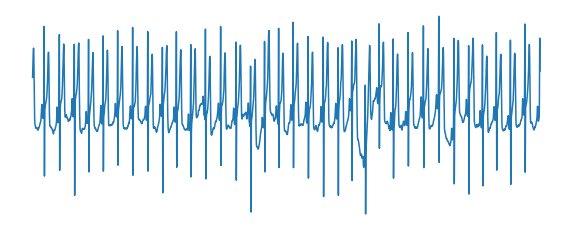

In [2]:
import wfdb # for reading .MAT/.HEA files 
import matplotlib.pyplot as plt # for plotting 
import pandas as pd 

#annotations File 
annotations_file = r"C:\Project\Research-Project\training2017\REFERENCE.csv"   
annotations = pd.read_csv(annotations_file) 
print(annotations.columns) 
 
processed_samples = [] 
 
#adding a column for storing the matlab files 
annotations["Matlab_files"] = annotations.apply(lambda x : 
r"C:\Project\Research-Project\training2017\\" + x["SampleID"], axis=1) 
#testing the matlab file addition 
print(annotations["Matlab_files"][0:4]) 
#looping over the matlab files dataframe 
for row in annotations.itertuples(): 
    current_record = wfdb.rdrecord(row.Matlab_files) 
    
    # 1. Set the figure size to keep the dimensions uniform for your GIF
    plt.figure(figsize=(10, 4)) 
    
    # 2. Plot the raw signal
    plt.plot(current_record.p_signal)
    
    # 3. CRITICAL: Completely strip the background, axes, labels, and ticks
    plt.axis('off') 
    
    # 4. Save with tight bounding boxes so there is no wasted white space
    current_sample_img = row.Matlab_files + "_without_axis.png" 
    plt.savefig(current_sample_img, dpi=300, bbox_inches='tight', pad_inches=0) 
    plt.close()


In [ ]:
import wfdb # for reading .MAT/.HEA files 
import matplotlib.pyplot as plt # for plotting 
import pandas as pd 

#annotations File 
annotations_file = r"C:\Project\Research-Project\training2017\REFERENCE.csv"   
annotations = pd.read_csv(annotations_file) 
print(annotations.columns) 
 
processed_samples = [] 
 
#adding a column for storing the matlab files 
annotations["Matlab_files"] = annotations.apply(lambda x : 
r"C:\Project\Research-Project\training2017\\" + x["SampleID"], axis=1) 
#testing the matlab file addition 
print(annotations["Matlab_files"][0:4]) 

for row in annotations.itertuples(): 
    current_record = wfdb.rdrecord(row.Matlab_files) 
    
    # 1. Set the figure size to keep the dimensions uniform for your GIF
    plt.figure(figsize=(10, 4)) 
    
    # 2. Plot the raw signal
    plt.plot(current_record.p_signal)
    
    # 3. CRITICAL: Completely strip the background, axes, labels, and ticks
    plt.axis('off') 
    
    # 4. Save with tight bounding boxes so there is no wasted white space
    current_sample_img = row.Matlab_files + ".png" 
    plt.savefig(current_sample_img, dpi=300, bbox_inches='tight', pad_inches=0) 
    plt.close()


In [8]:
from pathlib import Path
import imageio.v2 as imageio

# 1. Use Path() with a forward slash - Pathlib fixes Windows paths automatically
directory = Path("C:\Project\Research-Project\ECGPlots_from_individual_samples")

# 2. Grab all PNG files inside the directory
filenames = [f for f in directory.glob("*.png")]

# 3. Sort them by modification time (safest way to maintain order)
filenames.sort(key=lambda x: x.stat().st_mtime)

# 4. Read the first 20 images into your list
images = [imageio.imread(str(f)) for f in filenames[0:20]]

# 5. Compile and save the final GIF
output_gif_path = directory / "ecg_signals_animation.gif"
imageio.mimsave(str(output_gif_path), images, fps=2, loop=0)

print(f"Success! GIF successfully saved to: {output_gif_path}")


Success! GIF successfully saved to: C:\Project\Research-Project\ECGPlots_from_individual_samples\ecg_signals_animation.gif


In [11]:
from pathlib import Path
import imageio.v2 as imageio

directory = Path("C:\Project\Research-Project\ECGPlots_from_individual_samples")

# Grab and sort your transparent PNGs
filenames = [f for f in directory.glob("*.png")]
filenames.sort(key=lambda x: x.stat().st_mtime)

# Read the first 20 images
images = [imageio.imread(str(f)) for f in filenames[0:100]]

# SAVE THE GIF WITH TRANSPARENCY DISPOSAL
output_gif_path = directory / "ecg_signals_transparent_fast_top100.gif"

# 'disposal=2' forces the player to wipe the frame clean every 100ms (fps=10)
imageio.mimsave(str(output_gif_path), images, fps=10, loop=0, disposal=2)

print(f"Success! Perfect transparent, sequential GIF saved to: {output_gif_path}")


Success! Perfect transparent, sequential GIF saved to: C:\Project\Research-Project\ECGPlots_from_individual_samples\ecg_signals_transparent_fast_top100.gif


In [12]:
import os
import numpy as np
import imageio.v2 as imageio
from pathlib import Path

# 1. Define output path
output_dir = Path("C:\Project\Research-Project\Vice-City style Health bar")
output_dir.mkdir(parents=True, exist_ok=True)
output_gif_path = output_dir / "gta_vice_city_health_bar.gif"

# 2. Dimensions & Core Frames Setup
width, height = 400, 80
total_frames = 40
frames = []

# Color Config: Vice City Signature Neon Pink & Shadow Maroon
gta_pink = (255, 51, 153)       # Neon Pink
gta_shadow = (60, 10, 35)       # Dark Maroon Shadow Background
border_color = (255, 255, 255)  # Crisp White Border Frame

for i in range(total_frames):
    # Calculate health linear drop down to 10%
    health_pct = 1.0 - (i / (total_frames - 1)) * 0.9
    
    # Danger Zone: Blink every 3 frames if health drops below 35%
    is_visible = True
    if health_pct < 0.35 and (i // 3) % 2 == 0:
        is_visible = False
        
    # Create empty transparent canvas (RGBA)
    img = np.zeros((height, width, 4), dtype=np.uint8)
    
    # Define bounding dimensions for our bar
    x_start, x_end = 20, 380
    y_start, y_end = 25, 55
    
    # Calculate variable filling width
    current_x_end = int(x_start + (x_end - x_start) * health_pct)
    
    # Draw White Border Outline (Thick 2-pixel bounding frame)
    img[y_start-2:y_end+2, x_start-2:x_end+2, :3] = border_color
    img[y_start-2:y_end+2, x_start-2:x_end+2, 3] = 255
    
    # Draw Background Dark Shadow Space
    img[y_start:y_end, x_start:x_end, :3] = gta_shadow
    img[y_start:y_end, x_start:x_end, 3] = 255
    
    # Render Active Health Bar overlay (incorporating flashing trigger)
    if is_visible and current_x_end > x_start:
        img[y_start:y_end, x_start:current_x_end, :3] = gta_pink
        img[y_start:y_end, x_start:current_x_end, 3] = 255
        
    frames.append(img)

# 3. Compile frames into an infinite loop transparent GIF
# disposal=2 ensures clean overwrites on transparent slide surfaces
imageio.mimsave(str(output_gif_path), frames, fps=12, loop=0, disposal=2)

print(f"Grand success, pal! Vice City health bar exported to: {output_gif_path}")


Grand success, pal! Vice City health bar exported to: C:\Project\Research-Project\Vice-City style Health bar\gta_vice_city_health_bar.gif


GTA VC style health bar with health counter as well as a beathing heart

In [14]:
import os
import numpy as np
import imageio.v2 as imageio
from pathlib import Path

# 1. Output setup
output_dir = Path("C:\Project\Research-Project\Vice-City style Health bar")
output_dir.mkdir(parents=True, exist_ok=True)
output_gif_path = output_dir / "gta_vice_city_health_with_stats.gif"

# Canvas Dimensions: Made wider (520px) to comfortably fit the heart and numbers
width, height = 520, 80
total_frames = 40
frames = []

# Color Schemes
gta_pink = (255, 51, 153)       # Neon Pink
gta_shadow = (60, 10, 35)       # Deep Shadow Background
border_color = (255, 255, 255)  # Crisp White UI Outlines

# Simple 8x9 Pixel-Art Heart Mask (1 = Filled, 0 = Transparent)
heart_mask = np.array([
    [0,1,1,0,0,0,1,1,0],
    [1,1,1,1,0,1,1,1,1],
    [1,1,1,1,1,1,1,1,1],
    [1,1,1,1,1,1,1,1,1],
    [0,1,1,1,1,1,1,1,0],
    [0,0,1,1,1,1,1,0,0],
    [0,0,0,1,1,1,0,0,0],
    [0,0,0,0,1,0,0,0,0]
])

# 3-Pixel Scale-up function for a chunky, retro gaming look
def draw_pixel_sprite(img, mask, top_left_y, top_left_x, pixel_size, color):
    h_m, w_m = mask.shape
    for y in range(h_m):
        for x in range(w_m):
            if mask[y, x] == 1:
                y1 = top_left_y + y * pixel_size
                y2 = y1 + pixel_size
                x1 = top_left_x + x * pixel_size
                x2 = x1 + pixel_size
                img[y1:y2, x1:x2, :3] = color
                img[y1:y2, x1:x2, 3] = 255

# Simple 5x3 bitmap font dictionary for digits 0-9 and % symbol to keep everything pixelated
font_bitmap = {
    '0': [[1,1,1],[1,0,1],[1,0,1],[1,0,1],[1,1,1]],
    '1': [[0,1,0],[0,1,0],[0,1,0],[0,1,0],[0,1,0]],
    '2': [[1,1,1],[0,0,1],[1,1,1],[1,0,0],[1,1,1]],
    '3': [[1,1,1],[0,0,1],[1,1,1],[0,0,1],[1,1,1]],
    '4': [[1,0,1],[1,0,1],[1,1,1],[0,0,1],[0,0,1]],
    '5': [[1,1,1],[1,0,0],[1,1,1],[0,0,1],[1,1,1]],
    '6': [[1,1,1],[1,0,0],[1,1,1],[1,0,1],[1,1,1]],
    '7': [[1,1,1],[0,0,1],[0,0,1],[0,0,1],[0,0,1]],
    '8': [[1,1,1],[1,0,1],[1,1,1],[1,0,1],[1,1,1]],
    '9': [[1,1,1],[1,0,1],[1,1,1],[0,0,1],[1,1,1]],
    '%': [[1,0,1],[0,0,1],[0,1,0],[1,0,0],[1,0,1]]
}

def draw_string(img, text, start_y, start_x, pixel_size, color):
    current_x = start_x
    for char in text:
        if char in font_bitmap:
            bitmap = np.array(font_bitmap[char])
            draw_pixel_sprite(img, bitmap, start_y, current_x, pixel_size, color)
            current_x += (bitmap.shape[1] + 1) * pixel_size  # Add character spacing

for i in range(total_frames):
    # Calculate health drop down to 10%
    health_pct = 1.0 - (i / (total_frames - 1)) * 0.9
    health_val = int(health_pct * 100)
    
    # Blinking mechanism for danger zone (under 35%)
    is_visible = True
    if health_pct < 0.35 and (i // 3) % 2 == 0:
        is_visible = False
        
    # Generate blank transparent canvas
    img = np.zeros((height, width, 4), dtype=np.uint8)
    
    # --- DRAW RETRO HEART ICON ---
    # Placed on the far left (X: 20), scaled up for impact
    if is_visible or health_pct >= 0.35:
        draw_pixel_sprite(img, heart_mask, top_left_y=26, top_left_x=20, pixel_size=4, color=gta_pink)
    
    # --- DRAW HEALTH BAR ---
    # Shifted to the right to clear room for the heart
    x_start, x_end = 75, 415
    y_start, y_end = 25, 55
    current_x_end = int(x_start + (x_end - x_start) * health_pct)
    
    # White bounding box
    img[y_start-2:y_end+2, x_start-2:x_end+2, :3] = border_color
    img[y_start-2:y_end+2, x_start-2:x_end+2, 3] = 255
    
    # Dark background track shadow
    img[y_start:y_end, x_start:x_end, :3] = gta_shadow
    img[y_start:y_end, x_start:x_end, 3] = 255
    
    # Dynamic active pink filling
    if is_visible and current_x_end > x_start:
        img[y_start:y_end, x_start:current_x_end, :3] = gta_pink
        img[y_start:y_end, x_start:current_x_end, 3] = 255
        
    # --- DRAW LIVE TEXT VALUES ---
    # Placed on the far right (X: 435)
    text_string = f"{health_val}%"
    if is_visible or health_pct >= 0.35:
        draw_string(img, text_string, start_y=28, start_x=435, pixel_size=5, color=border_color)
        
    frames.append(img)

# 3. Export with seamless transparent disposal frames
imageio.mimsave(str(output_gif_path), frames, fps=12, loop=0, disposal=2)

print(f"Success, pal! Advanced Vice City tracker with heart and stats saved to: {output_gif_path}")


Success, pal! Advanced Vice City tracker with heart and stats saved to: C:\Project\Research-Project\Vice-City style Health bar\gta_vice_city_health_with_stats.gif


ECG single sample with pink gridlines

In [21]:
import matplotlib.pyplot as plt
import wfdb
from pathlib import Path

# 1. Setup the directory path
directory = Path("C:\Project\Research-Project\Vice-City style Health bar")
directory.mkdir(parents=True, exist_ok=True)

# 2. Load a sample record (Replace with your actual row data source line)
# For demonstration, we assume you have 'current_record' from your annotations loop
Matlab_files = r"C:\Project\Research-Project\training2017\A03488"
current_record = wfdb.rdrecord(Matlab_files)
signal_data = current_record.p_signal

# Let's use a placeholder variable name for your loop integration
def save_ecg_with_medical_grid(signal_data, output_filename):
    # Create the figure with a solid white canvas background
    fig, ax = plt.subplots(figsize=(10, 4), facecolor='white')
    
    # Plot the dark charcoal/black ECG wave on top of the grid
    ax.plot(signal_data, color='#2C3E50', lw=2, zorder=3)
    
    # Define medical grid colors (Classic hospital pink/red)
    major_grid_color = '#FFB6C1'  # Light Pink (Major blocks)
    minor_grid_color = '#FFE4E1'  # Misty Rose / Lighter Pink (Minor blocks)
    
    # Turn on the grid infrastructure
    ax.grid(True, which='major', color=major_grid_color, linestyle='-', linewidth=1.2, zorder=1)
    ax.grid(True, which='minor', color=minor_grid_color, linestyle='-', linewidth=0.6, zorder=1)
    
    # Force the grid density to match clinical paper styles
    # Adjust these limits based on your actual sample array length (e.g., 0 to 3000)
    ax.set_xlim(0, len(signal_data))
    
    # Automatically set major grid ticks every 100 samples, minor ticks every 20 samples
    ax.xaxis.set_major_locator(plt.MultipleLocator(100))
    ax.xaxis.set_minor_locator(plt.MultipleLocator(20))
    
    # Do the same for the vertical amplitude grid ticks
    ax.yaxis.set_major_locator(plt.MultipleLocator(0.5))
    ax.yaxis.set_minor_locator(plt.MultipleLocator(0.1))
    
    # CRITICAL: Completely hide the black frame borders and axis text labels
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(axis='both', which='both', length=0) # Removes the little tick dashes
    
    # Save the file with zero white margins
    output_path = directory / output_filename
    plt.savefig(str(output_path), dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close()
    print(f"Grand success! Grid ECG saved to: {output_path}")

# To run it inside your loop, you would simply call:
save_ecg_with_medical_grid(current_record.p_signal, "paper_grid_sample.png")


Grand success! Grid ECG saved to: C:\Project\Research-Project\Vice-City style Health bar\paper_grid_sample.png


Stitching 3 samples to generate a singl PNG where sections inside the samples are highlighted 

In [25]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import random
from pathlib import Path

import wfdb # for reading .MAT/.HEA files 
import matplotlib.pyplot as plt # for plotting 
import pandas as pd 

#annotations File 
annotations_file = r"C:\Project\Research-Project\training2017\REFERENCE.csv"   
annotations = pd.read_csv(annotations_file) 
print(annotations.columns) 
 
processed_samples = [] 
 
#adding a column for storing the matlab files 
annotations["Matlab_files"] = annotations.apply(lambda x : 
r"C:\Project\Research-Project\training2017\\" + x["SampleID"], axis=1) 
 



# 1. Setup the directory path
directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_ai_highlight_plot(annotations_dataframe):
    """
    Takes multiple samples, chains them together, and highlights random sections.
    Pass your 'annotations' object or a slice of it into this function.
    """
    combined_signal = []
    
    # Grab data from the first 4 rows to create a long continuous stream
    for row in annotations_dataframe.head(4).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        # Flatten the 2D array if it's dual-channel, or just grab the main signal
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
    
    combined_signal = np.array(combined_signal)
    total_length = len(combined_signal)
    
    # Set up the figure (Solid white or keep it clear to blend with your slides)
    fig, ax = plt.subplots(figsize=(12, 4), facecolor='white')
    
    # Plot the continuous ECG data line in a muted grey so the highlights pop out
    ax.plot(combined_signal, color='#7F8C8D', lw=1.5, zorder=2)
    
    # Pick a few random window sizes to highlight (e.g., width of a chaotic rhythm segment)
    # We will pick 3 random locations across the long signal timeline
    num_highlights = 3
    window_width = 180  # Number of samples wide for the highlight box
    
    # Generate random start points, ensuring they don't overshoot the total length
    random_starts = [
        random.randint(200, int(total_length * 0.3)),
        random.randint(int(total_length * 0.4), int(total_length * 0.6)),
        random.randint(int(total_length * 0.7), int(total_length * 0.9))
    ]
    
    # Highlight colors: Neon Cyan/Green for standard AI scanning, and Vice City Pink for the detected AF anomaly!
    highlight_colors = ['#00FFFF', '#00FF66', '#FF3399'] 
    highlight_labels = ['Normal Rhythm', 'Artifact Filtered', 'AF Anomaly Detected!']
    
    for idx, start_pos in enumerate(random_starts):
        end_pos = start_pos + window_width
        color = highlight_colors[idx]
        
        # CRITICAL LINE: Draw a vertical bounding highlight block behind the text but over the wave
        ax.axvspan(start_pos, end_pos, color=color, alpha=0.25, zorder=1)
        
        # Add a subtle dotted boundary line on the edges of the box for an engineering look
        ax.axvline(start_pos, color=color, linestyle=':', alpha=0.6, lw=1.5, zorder=1)
        ax.axvline(end_pos, color=color, linestyle=':', alpha=0.6, lw=1.5, zorder=1)
        
        # Add text labels right above the highlight box
        ax.text(start_pos + (window_width/2), max(combined_signal)*1.05, highlight_labels[idx], 
                color='#2C3E50', fontsize=9, weight='bold', ha='center', zorder=4)

    # Clean up formatting: Hide all borders, ticks, and numbers
    ax.set_xlim(0, total_length)
    ax.set_ylim(min(combined_signal)*1.2, max(combined_signal)*1.3) # Give room for labels
    
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)
    ax.spines['bottom'].set_visible(False)
    ax.spines['left'].set_visible(False)
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    ax.tick_params(axis='both', which='both', length=0)
    
    # Save the output image
    output_path = directory / "ai_spotlight_highlights.png"
    plt.savefig(str(output_path), dpi=300, bbox_inches='tight', pad_inches=0)
    plt.close()
    print(f"Grand success! AI spotlight visual saved to: {output_path}")

# To run it in your script, simply call:
generate_ai_highlight_plot(annotations)


Index(['SampleID', 'Inference'], dtype='object')
Grand success! AI spotlight visual saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ai_spotlight_highlights.png


A fast moving ECG showing 3 samples stitched together

In [27]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# 1. Setup the directory path
directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_sliding_window_gif(annotations_dataframe):
    # Chain the first 4 samples together into one long continuous stream
    combined_signal = []
    for row in annotations_dataframe.head(4).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
        
    combined_signal = np.array(combined_signal)
    total_length = len(combined_signal)
    
    # Sliding Window parameters
    window_width = 800   # How many ECG samples are visible on screen at once
    step_size = 60       # How fast the screen scrolls forward per frame
    
    # Pin down a fixed anomaly highlight box relative to the overall timeline 
    # (Let's place it right in the middle of our long chained signal stream)
    anomaly_start = int(total_length * 0.45)
    anomaly_end = anomaly_start + 250
    vice_city_pink = '#FF3399'
    
    frame_paths = []
    frame_counter = 0
    
    # Slide the window start position across the continuous timeline
    # We stop when the window's right edge hits the end of our data stream
    for start_idx in range(0, total_length - window_width, step_size):
        end_idx = start_idx + window_width
        
        # Setup clean figure canvas
        fig, ax = plt.subplots(figsize=(10, 4))
        
        # Plot the moving slice of the signal in an elegant slate grey
        ax.plot(combined_signal, color='#7F8C8D', lw=2, zorder=2)
        
        # CRITICAL WINDOW SHIFT: Move the x-axis view to follow our sliding indices
        ax.set_xlim(start_idx, end_idx)
        
        # Set dynamic y-limits based on the local max/min inside the visible frame so it fits nicely
        local_slice = combined_signal[start_idx:end_idx]
        ax.set_ylim(min(local_slice) * 1.2, max(local_slice) * 1.4)
        
        # --- DYNAMIC AI SPOTLIGHT OVERLAY ---
        # If our moving screen intersects with the designated anomaly zone, render the highlight!
        if end_idx > anomaly_start and start_idx < anomaly_end:
            # Calculate overlapping bounding box boundaries relative to what is currently visible on screen
            box_left = max(start_idx, anomaly_start)
            box_right = min(end_idx, anomaly_end)
            
            # Paint the transparent Vice City pink highlight box overlay
            ax.axvspan(box_left, box_right, color=vice_city_pink, alpha=0.25, zorder=1)
            ax.axvline(box_left, color=vice_city_pink, linestyle=':', alpha=0.6, lw=1.5, zorder=1)
            ax.axvline(box_right, color=vice_city_pink, linestyle=':', alpha=0.6, lw=1.5, zorder=1)
            
            # Float the warning text string right over the moving box
            ax.text(box_left + (box_right - box_left)/2, max(local_slice) * 1.1, "AF Anomaly Detected!", 
                    color='#2C3E50', fontsize=10, weight='bold', ha='center', zorder=4)
        
        # Wipe all background frames, ticks, numbers and text labels for transparency layout
        ax.axis('off')
        
        # Save temporary frame image file
        frame_filename = directory / f"slide_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=150, bbox_inches='tight', pad_inches=0, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1
        
        # Cap the frames around 50 files so the final GIF compile doesn't bloat memory
        if frame_counter >= 50:
            break

    # 2. Compile moving frame image files into a looping transparent movie file
    print("Compiling smooth scrolling frames into a transparent GIF...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_live_scrolling_monitor.gif"
    # fps=15 creates an incredibly smooth, continuous monitor refresh movement
    imageio.mimsave(str(output_gif_path), images, fps=15, loop=0, disposal=2)
    
    # 3. Clean up the messy temp PNG images from the directory
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Real-time scrolling monitor saved to: {output_gif_path}")

# Run it using your base DataFrame:
generate_sliding_window_gif(annotations)


Compiling smooth scrolling frames into a transparent GIF...
Grand success, pal! Real-time scrolling monitor saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_live_scrolling_monitor.gif


Same as above but slowed down

In [29]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# 1. Setup the directory path
directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_slowed_scrolling_gif(annotations_dataframe):
    # Chain the first 4 samples together into one long continuous stream
    combined_signal = []
    for row in annotations_dataframe.head(4).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
        
    combined_signal = np.array(combined_signal)
    total_length = len(combined_signal)
    
    # SLOWDOWN FIX: Smaller window steps make the camera crawl forward much more slowly
    window_width = 800   # Visible window size
    step_size = 30       # Cut in half (from 60 to 30) to slow down the scroll speed
    
    # Set up our three distinct milestone highlight zones across the full timeline length
    highlight_zones = [
        {"start": int(total_length * 0.15), "end": int(total_length * 0.15) + 180, "color": '#00FFFF', "label": "Normal Rhythm"},
        {"start": int(total_length * 0.45), "end": int(total_length * 0.45) + 180, "color": '#00FF66', "label": "Artifact Filtered"},
        {"start": int(total_length * 0.75), "end": int(total_length * 0.75) + 180, "color": '#FF3399', "label": "AF Anomaly Detected!"}
    ]
    
    frame_paths = []
    frame_counter = 0
    
    # Slide the window start index across the full long continuous data array
    for start_idx in range(0, total_length - window_width, step_size):
        end_idx = start_idx + window_width
        
        # Setup clean figure canvas
        fig, ax = plt.subplots(figsize=(10, 4))
        
        # Plot the moving signal line
        ax.plot(combined_signal, color='#7F8C8D', lw=2, zorder=2)
        
        # Lock camera tracking boundaries
        ax.set_xlim(start_idx, end_idx)
        
        # Dynamic Y scaling to keep waves beautifully framed
        local_slice = combined_signal[start_idx:end_idx]
        ax.set_ylim(min(local_slice) * 1.2, max(local_slice) * 1.5)
        
        # --- MULTI-LABEL SPOTLIGHT LOGIC ---
        # Loop through our three zones and check which ones are currently crossing our monitor screen view
        for zone in highlight_zones:
            z_start = zone["start"]
            z_end = zone["end"]
            
            if end_idx > z_start and start_idx < z_end:
                box_left = max(start_idx, z_start)
                box_right = min(end_idx, z_end)
                
                # Render the translucent colored scanning block
                ax.axvspan(box_left, box_right, color=zone["color"], alpha=0.25, zorder=1)
                ax.axvline(box_left, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                ax.axvline(box_right, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                
                # Render the tracking label right above the wave segment
                ax.text(box_left + (box_right - box_left)/2, max(local_slice) * 1.15, zone["label"], 
                        color='#2C3E50', fontsize=10, weight='bold', ha='center', zorder=4)
        
        # Clean background formatting (maintains transparency framework)
        ax.axis('off')
        
        # Save temporary frame image file
        frame_filename = directory / f"slow_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=150, bbox_inches='tight', pad_inches=0, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1
        
        # Bump up frame cap to 80 so all three zones have time to pass by the camera lens
        if frame_counter >= 80:
            break

    # 2. Compile moving frame images into looping transparent movie file
    print("Compiling slow scrolling frames into final transparent GIF...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_slow_scrolling_monitor.gif"
    # SLOWDOWN FIX: Set fps to 10 for a natural, steady patient monitor pacing rate
    imageio.mimsave(str(output_gif_path), images, fps=10, loop=0, disposal=2)
    
    # 3. Automatic clean up of temporary files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Slow-scrolling multi-zone monitor saved to: {output_gif_path}")

# Run it using your base DataFrame:
generate_slowed_scrolling_gif(annotations)


Compiling slow scrolling frames into final transparent GIF...
Grand success, pal! Slow-scrolling multi-zone monitor saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_slow_scrolling_monitor.gif


In [30]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_fixed_scrolling_gif(annotations_dataframe):
    # 1. Grab enough signal data
    combined_signal = []
    for row in annotations_dataframe.head(3).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
        
    # CRITICAL FIX: We isolate a clean 4,500-sample chunk so our loop covers the whole timeline
    combined_signal = np.array(combined_signal)[:4500]
    
    window_width = 800   # Keep the viewing screen width fixed
    step_size = 45       # Pacing step size for a steady, smooth scroll
    
    # CRITICAL FIX: Set absolute pixel index positions for the zones so they fit within the 4500 limit
    highlight_zones = [
        {"start": 600,  "end": 850,  "color": '#00FFFF', "label": "Normal Rhythm"},
        {"start": 1800, "end": 2050, "color": '#00FF66', "label": "Artifact Filtered"},
        {"start": 3000, "end": 3250, "color": '#FF3399', "label": "AF Anomaly Detected!"}
    ]
    
    frame_paths = []
    frame_counter = 0
    
    # 2. Slide window forward until it reaches the end of our focused signal block
    for start_idx in range(0, len(combined_signal) - window_width, step_size):
        end_idx = start_idx + window_width
        
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.plot(combined_signal, color='#7F8C8D', lw=2, zorder=2)
        
        # Camera window viewport boundaries
        ax.set_xlim(start_idx, end_idx)
        
        # Keep vertical window perfectly centered on local values
        local_slice = combined_signal[start_idx:end_idx]
        if len(local_slice) > 0:
            ax.set_ylim(min(local_slice) * 1.2, max(local_slice) * 1.5)
        
        # Draw visible highlight blocks crossing the lens
        for zone in highlight_zones:
            if end_idx > zone["start"] and start_idx < zone["end"]:
                box_left = max(start_idx, zone["start"])
                box_right = min(end_idx, zone["end"])
                
                ax.axvspan(box_left, box_right, color=zone["color"], alpha=0.25, zorder=1)
                ax.axvline(box_left, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                ax.axvline(box_right, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                
                # Dynamic text placement right over the wave
                ax.text(box_left + (box_right - box_left)/2, max(local_slice) * 1.15, zone["label"], 
                        color='#2C3E50', fontsize=10, weight='bold', ha='center', zorder=4)
        
        ax.axis('off')
        
        # Save temporary frame files
        frame_filename = directory / f"fixed_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=120, bbox_inches='tight', pad_inches=0, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    print(f"Compiling {len(frame_paths)} sequential frames into the final animation...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_perfect_scrolling_monitor.gif"
    imageio.mimsave(str(output_gif_path), images, fps=12, loop=0, disposal=2)
    
    # 3. Clean up the temp images from disk
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Complete multi-zone monitor saved to: {output_gif_path}")

# Run it using your base DataFrame:
generate_fixed_scrolling_gif(annotations)


Compiling 83 sequential frames into the final animation...


ValueError: all input arrays must have the same shape

In [32]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_fixed_scrolling_gif(annotations_dataframe):
    # 1. Grab signal data
    combined_signal = []
    for row in annotations_dataframe.head(3).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
        
    combined_signal = np.array(combined_signal)[:4500]
    
    window_width = 800   
    step_size = 45       
    
    # Absolute positions for your three showcase milestones
    highlight_zones = [
        {"start": 600,  "end": 850,  "color": '#00FFFF', "label": "Normal Rhythm"},
        {"start": 1800, "end": 2050, "color": '#00FF66', "label": "Artifact Filtered"},
        {"start": 3000, "end": 3250, "color": '#FF3399', "label": "AF Anomaly Detected!"}
    ]
    
    # BUZZKILL FIX 1: Lock global vertical bounds across the whole array to keep shapes identical
    global_min = min(combined_signal) * 1.3
    global_max = max(combined_signal) * 1.5
    
    frame_paths = []
    frame_counter = 0
    
    for start_idx in range(0, len(combined_signal) - window_width, step_size):
        end_idx = start_idx + window_width
        
        # Use subplots_adjust to hard-code strict pixel boundaries
        fig, ax = plt.subplots(figsize=(10, 4))
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1) # Forces edge-to-edge canvas matching
        
        ax.plot(combined_signal, color='#7F8C8D', lw=2, zorder=2)
        
        # Track scrolling camera window
        ax.set_xlim(start_idx, end_idx)
        ax.set_ylim(global_min, global_max) # Locked global heights
        
        # Draw highlight boxes crossing the viewport lens
        for zone in highlight_zones:
            if end_idx > zone["start"] and start_idx < zone["end"]:
                box_left = max(start_idx, zone["start"])
                box_right = min(end_idx, zone["end"])
                
                ax.axvspan(box_left, box_right, color=zone["color"], alpha=0.25, zorder=1)
                ax.axvline(box_left, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                ax.axvline(box_right, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                
                # Render tracking text labels right over the center profile
                ax.text(box_left + (box_right - box_left)/2, max(combined_signal) * 1.1, zone["label"], 
                        color='#2C3E50', fontsize=10, weight='bold', ha='center', zorder=4)
        
        ax.axis('off')
        
        # Save temporary frame files
        frame_filename = directory / f"fixed_frame_{frame_counter:04d}.png"
        
        # BUZZKILL FIX 2: Drop bbox_inches='tight' so Matplotlib doesn't modify frame dimensions per image
        plt.savefig(str(frame_filename), dpi=120, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    print(f"Compiling {len(frame_paths)} identical frames into the final animation...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_perfect_scrolling_monitor.gif"
    imageio.mimsave(str(output_gif_path), images, fps=12, loop=0, disposal=2)
    
    # 3. Clean up the disk footprint files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Complete multi-zone monitor saved to: {output_gif_path}")

# Run it using your base DataFrame:
generate_fixed_scrolling_gif(annotations)


Compiling 83 identical frames into the final animation...
Grand success, pal! Complete multi-zone monitor saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_perfect_scrolling_monitor.gif


In [33]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_slow_scrolling_gif(annotations_dataframe):
    # 1. Grab signal data
    combined_signal = []
    for row in annotations_dataframe.head(3).itertuples():
        current_record = wfdb.rdrecord(row.Matlab_files)
        signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
        combined_signal.extend(signal)
        
    combined_signal = np.array(combined_signal)[:4500]
    
    window_width = 800   
    
    # SLOWDOWN FIX: Dropping step size to 20 makes the movement much more deliberate
    step_size = 20       
    
    # Absolute positions for your three showcase milestones
    highlight_zones = [
        {"start": 600,  "end": 850,  "color": '#00FFFF', "label": "Normal Rhythm"},
        {"start": 1800, "end": 2050, "color": '#00FF66', "label": "Artifact Filtered"},
        {"start": 3000, "end": 3250, "color": '#FF3399', "label": "AF Anomaly Detected!"}
    ]
    
    # Lock global vertical bounds across the whole array to keep shapes identical
    global_min = min(combined_signal) * 1.3
    global_max = max(combined_signal) * 1.5
    
    frame_paths = []
    frame_counter = 0
    
    for start_idx in range(0, len(combined_signal) - window_width, step_size):
        end_idx = start_idx + window_width
        
        # Keep strict pixel dimensions
        fig, ax = plt.subplots(figsize=(10, 4))
        fig.subplots_adjust(left=0, right=1, bottom=0, top=1) 
        
        ax.plot(combined_signal, color='#7F8C8D', lw=2, zorder=2)
        
        # Track scrolling camera window
        ax.set_xlim(start_idx, end_idx)
        ax.set_ylim(global_min, global_max) 
        
        # Draw highlight boxes crossing the viewport lens
        for zone in highlight_zones:
            if end_idx > zone["start"] and start_idx < zone["end"]:
                box_left = max(start_idx, zone["start"])
                box_right = min(end_idx, zone["end"])
                
                ax.axvspan(box_left, box_right, color=zone["color"], alpha=0.25, zorder=1)
                ax.axvline(box_left, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                ax.axvline(box_right, color=zone["color"], linestyle=':', alpha=0.6, lw=1.5, zorder=1)
                
                # Render tracking text labels right over the center profile
                ax.text(box_left + (box_right - box_left)/2, max(combined_signal) * 1.1, zone["label"], 
                        color='#2C3E50', fontsize=10, weight='bold', ha='center', zorder=4)
        
        ax.axis('off')
        
        # Save temporary frame files
        frame_filename = directory / f"fixed_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=120, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    print(f"Compiling {len(frame_paths)} sequential frames into the final animation...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_perfect_scrolling_monitor.gif"
    # Keep FPS at 12 to ensure the movement doesn't become laggy or choppy
    imageio.mimsave(str(output_gif_path), images, fps=12, loop=0, disposal=2)
    
    # 3. Clean up disk files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Slowed multi-zone monitor saved to: {output_gif_path}")

# Run it using your base DataFrame:
generate_slow_scrolling_gif(annotations)


Compiling 185 sequential frames into the final animation...
Grand success, pal! Slowed multi-zone monitor saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_perfect_scrolling_monitor.gif


In [34]:
annotations.head()

,SampleID,Inference,Matlab_files
0,A00001,N,C:\Project\Research-Project\training2017\\A00001
1,A00002,N,C:\Project\Research-Project\training2017\\A00002
2,A00003,N,C:\Project\Research-Project\training2017\\A00003
3,A00004,A,C:\Project\Research-Project\training2017\\A00004
4,A00005,A,C:\Project\Research-Project\training2017\\A00005


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Set up the target export path
directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# Human-readable dictionary mapping your target labels to clinical descriptions
LABEL_MAP = {
    'N': 'Normal Rhythm',
    'A': 'Atrial Fibrillation (AF)',
    'O': 'Other Cardiac Ailment',
    '~': 'Noisy Sample (Artifacts)'
}

def generate_dynamic_hud_gif(annotations_dataframe):
    frame_paths = []
    frame_counter = 0
    
    # Grab the first 25 samples directly from your dataframe schema
    # Using head(25) prevents any 'map object' slicing errors
    for row in annotations_dataframe.head(25).itertuples():
        # 1. Dynamically read the raw signal from the Matlab file path
        try:
            current_record = wfdb.rdrecord(row.Matlab_files)
            signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
            # Clip each signal to a uniform 1000 data points so they look standardized
            signal = signal[:1000]
        except Exception as e:
            # Skip any missing files safely without breaking the loop
            continue
            
        # 2. Map the structural inference label to its clinical meaning
        inference_code = str(row.Inference).strip()
        clinical_text = LABEL_MAP.get(inference_code, 'Unknown Status')
        
        # Color coding the text label to stand out dynamically
        if inference_code == 'A':
            text_color = '#FF3399'  # Vice City Pink for dangerous AF
        elif inference_code == 'N':
            text_color = "#B2BDBA"  # Neon Cyan/Green for clean health
        else:
            text_color = '#FFCC00'  # Neon Yellow warning for noisy/other alerts
            
        # 3. Initialize a perfectly uniform figure box
        fig, ax = plt.subplots(figsize=(10, 4.5))
        # Hard-code strict edge alignments to lock identical image sizes
        fig.subplots_adjust(left=0, right=1, bottom=0, top=0.85)
        
        # Plot the clean, crisp dark wave line
        ax.plot(signal, color='#2C3E50', lw=2, zorder=2)
        
        # Set absolute boundaries to force identical image dimensions for imageio
        ax.set_xlim(0, 1000)
        ax.set_ylim(-2.5, 3.5)  # Global uniform vertical limit matching standard ECG ranges
        
        # --- THE DYNAMIC HUD OVERLAY ---
        # Draw the Sample ID on the top-left of the canvas
        ax.text(30, 2.8, f"SAMPLE: {row.SampleID}", color='#2C3E50', 
                fontsize=11, weight='bold', ha='left', zorder=4)
                
        # Draw the mapped Inference Status description on the top-right
        ax.text(970, 2.8, f"STATUS: {clinical_text}", color=text_color, 
                fontsize=11, weight='bold', ha='right', zorder=4)
        
        # Strip all background borders, grids, numbers and frames for transparent export
        ax.axis('off')
        
        # Save frame with strict size parameters to disk
        frame_filename = directory / f"hud_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=120, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    # 4. Compile the sequential frames into a single transparent loop
    print(f"Compiling {len(frame_paths)} identical HUD frames into the final presentation GIF...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_dynamic_hud_showcase.gif"
    # fps=3 means a new patient record flashes on screen every 333 milliseconds
    imageio.mimsave(str(output_gif_path), images, fps=3, loop=0, disposal=2)
    
    # 5. Clean up temporary footprint files automatically
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Transparent HUD showcase saved to: {output_gif_path}")

# To deploy it, pass your annotations dataframe right into the function:
generate_dynamic_hud_gif(annotations)


Compiling 25 identical HUD frames into the final presentation GIF...
Grand success, pal! Transparent HUD showcase saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_dynamic_hud_showcase.gif


Reading 1000s  of labelled Physionet CG samples 

In [37]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Explicitly tell Matplotlib to use Arial font globally for crisp text rendering
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# High-contrast mapping for white and light pink backgrounds
LABEL_MAP = {
    'N': 'Normal Rhythm',
    'A': 'Atrial Fibrillation (AF)',
    'O': 'Other Cardiac Ailment',
    '~': 'Noisy Sample (Artifacts)'
}

def generate_dynamic_hud_gif(annotations_dataframe):
    frame_paths = []
    frame_counter = 0
    
    # Grab the first 25 samples
    for row in annotations_dataframe.head(25).itertuples():
        try:
            current_record = wfdb.rdrecord(row.Matlab_files)
            signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
            signal = signal[:1000]
        except Exception as e:
            continue
            
        inference_code = str(row.Inference).strip()
        clinical_text = LABEL_MAP.get(inference_code, 'Unknown Status')
        
        # HIGH CONTRAST COLOR CONFIGURATION (Optimized for light pink/white slides)
        # Deep charcoal/black for maximum readability on light surfaces
        base_dark = '#1A252C'  
        
        if inference_code == 'A':
            text_color = '#D81B60'  # Deep Vice City Crimson Pink (Pops on light pink grid)
        elif inference_code == 'N':
            text_color = '#006644'  # Deep Forest Green (Highly readable on white/pink)
        else:
            text_color = '#8A6D3B'  # Dark Mustard/Amber warning tone
            
        # Initialize uniform figure frame box with extra headroom for larger fonts
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.subplots_adjust(left=0.02, right=0.98, bottom=0, top=0.80) # Added margin padding to protect edges
        
        # Plot the main heartbeat wave line in clean high-contrast charcoal
        ax.plot(signal, color=base_dark, lw=2.5, zorder=2)
        
        ax.set_xlim(0, 1000)
        ax.set_ylim(-2.5, 3.5)  
        
        # --- ENHANCED BIG ARIAL HUD OVERLAY ---
        # Draw Sample ID on the Left
        ax.text(30, 2.8, f"SAMPLE: {row.SampleID}", color=base_dark, 
                fontname='Arial', fontsize=15, weight='black', ha='left', zorder=4)
                
        # Draw Mapped Inference Status on the Right
        ax.text(970, 2.8, f"STATUS: {clinical_text}", color=text_color, 
                fontname='Arial', fontsize=15, weight='black', ha='right', zorder=4)
        
        ax.axis('off')
        
        frame_filename = directory / f"hud_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=120, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    print(f"Compiling {len(frame_paths)} high-contrast frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_high_contrast_hud.gif"
    imageio.mimsave(str(output_gif_path), images, fps=3, loop=0, disposal=2)
    
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! High-contrast Arial HUD showcase saved to: {output_gif_path}")

# Run it:
generate_dynamic_hud_gif(annotations)


Compiling 25 high-contrast frames...
Grand success, pal! High-contrast Arial HUD showcase saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_high_contrast_hud.gif


feeding the ECG to CNN 

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce the same global Arial typeface
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_cnn_filtering_gif(annotations_dataframe):
    # 1. Isolate just one single clean heartbeat sample for the CNN demonstration
    row = list(annotations_dataframe.head(1).itertuples())[0]
    current_record = wfdb.rdrecord(row.Matlab_files)
    signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
    
    # Crop to exactly one clear window segment (e.g., 400 data points containing a clear QRS complex)
    signal = signal[100:500]
    total_length = len(signal)
    
    frame_paths = []
    frame_counter = 0
    
    # CNN Filter settings
    filter_width = 25
    step_size = 8  # Controls the animation speed of the sliding filter
    
    base_dark = '#1A252C'
    cnn_cyan = '#00D2FF'  # High contrast electric cyan for the CNN operation layer
    
    # 2. Slide the convolutional kernel window across the heartbeat timeline
    for start_idx in range(0, total_length - filter_width, step_size):
        end_idx = start_idx + filter_width
        
        # Setup standard frame canvas dimension parameters to maintain identical sizes
        fig, ax = plt.subplots(figsize=(10, 5))
        fig.subplots_adjust(left=0.02, right=0.98, bottom=0, top=0.80)
        
        # Plot the primary target ECG wave
        ax.plot(signal, color=base_dark, lw=2.5, zorder=2)
        
        # Absolute frame locks to satisfy imageio requirements
        ax.set_xlim(0, total_length)
        ax.set_ylim(-2.5, 3.5)
        
        # --- THE SLIDING CONVOLUTION KERNEL OVERLAY ---
        # Paint the active 1D convolutional filter box moving from left to right
        ax.axvspan(start_idx, end_idx, color=cnn_cyan, alpha=0.3, zorder=1)
        ax.axvline(start_idx, color=cnn_cyan, linestyle='-', alpha=0.8, lw=2, zorder=1)
        ax.axvline(end_idx, color=cnn_cyan, linestyle='-', alpha=0.8, lw=2, zorder=1)
        
        # --- MATHEMATICAL FEATURE EXTRACTION TRACE ---
        # Draw a simulated extracted "Feature Map" curve underneath the active signal
        # This shows the mathematical path left behind by the sliding kernel matrix
        feature_map = np.zeros(total_length)
        # Calculate localized mathematical variance inside past window positions to look like a real feature map
        for t in range(0, start_idx, step_size):
            if t + filter_width < total_length:
                feature_map[t + (filter_width // 2)] = np.std(signal[t:t+filter_width]) * 1.5 - 1.8
                
        # Only plot the extracted features up to the current filter location
        if start_idx > 0:
            ax.plot(feature_map[:start_idx], color=cnn_cyan, lw=2, linestyle='--', zorder=3)
            
        # --- ARIAL HUD ANNOTATIONS ---
        ax.text(30, 2.8, f"INPUT: {row.SampleID} (Single-Lead ECG Source)", color=base_dark, 
                fontname='Arial', fontsize=15, weight='black', ha='left', zorder=4)
                
        ax.text(970, 2.8, "1D-CNN: Feature Map Extraction...", color=cnn_cyan, 
                fontname='Arial', fontsize=15, weight='black', ha='right', zorder=4)
        
        ax.axis('off')
        
        # Save temporary frame image file
        frame_filename = directory / f"cnn_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=120, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    print(f"Compiling {len(frame_paths)} uniform CNN filtering frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_cnn_feature_extraction.gif"
    # fps=12 creates a smooth, continuous scanning motion across the slide
    imageio.mimsave(str(output_gif_path), images, fps=12, loop=0, disposal=2)
    
    # 3. Clean up the disk footprint files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Transparent CNN scanning visual saved to: {output_gif_path}")

# Run it:
generate_cnn_filtering_gif(annotations)


Compiling 47 uniform CNN filtering frames...
Grand success, pal! Transparent CNN scanning visual saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_cnn_feature_extraction.gif


Spli scene Math

In [40]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial fonts
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_cnn_input_output_gif(annotations_dataframe):
    # 1. Isolate one clear heartbeat sample
    row = list(annotations_dataframe.head(1).itertuples())[0]
    current_record = wfdb.rdrecord(row.Matlab_files)
    signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
    
    # Clip to a clean 400-sample heartbeat profile containing a sharp QRS complex
    signal = signal[100:500]
    total_length = len(signal)
    
    frame_paths = []
    frame_counter = 0
    
    # CNN Configuration
    filter_width = 25
    step_size = 10  # Animation step rate
    
    base_dark = '#1A252C'   # Charcoal for raw data
    cnn_cyan = '#0083B0'    # Mid-tone Cyan for processing
    output_pink = '#D81B60' # Vice City Crimson for output features
    
    # Pre-calculate the output feature activations based on signal changes (slopes/variance)
    # This represents the true 'output array' of a convolutional layer
    activation_points = []
    for t in range(0, total_length - filter_width, step_size):
        # Calculate local gradient change inside the sliding window
        local_window = signal[t:t+filter_width]
        variance_score = np.std(local_window)
        activation_points.append(variance_score)
    
    activation_points = np.array(activation_points)
    # Normalize between 0 and 1 for clean color mapping
    norm_activations = (activation_points - min(activation_points)) / (max(activation_points) - min(activation_points) + 1e-5)
    
    # 2. Loop to build the pipeline frames
    steps = list(range(0, total_length - filter_width, step_size))
    for i, start_idx in enumerate(steps):
        end_idx = start_idx + filter_width
        
        # Open an expanded figure to clearly split Input vs Output stacked layers
        fig, (ax_in, ax_out) = plt.subplots(2, 1, figsize=(10, 6))
        fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.85, hspace=0.3)
        
        # --- TOP SCREEN: THE INPUT (RAW ECG) ---
        ax_in.plot(signal, color=base_dark, lw=2.5, zorder=2)
        ax_in.axvspan(start_idx, end_idx, color=cnn_cyan, alpha=0.25, zorder=1)
        ax_in.axvline(start_idx, color=cnn_cyan, linestyle='-', alpha=0.7, lw=2, zorder=1)
        ax_in.axvline(end_idx, color=cnn_cyan, linestyle='-', alpha=0.7, lw=2, zorder=1)
        
        ax_in.set_xlim(0, total_length)
        ax_in.set_ylim(-2.5, 3.5)
        ax_in.axis('off')
        ax_in.text(10, 2.7, "INPUT: Raw Single-Lead Signal", color=base_dark, 
                   fontsize=14, weight='black', ha='left')
        
        # --- BOTTOM SCREEN: THE OUTPUT (NUMERICAL FEATURE MAP) ---
        # Draw the resulting output nodes as a horizontal matrix grid
        grid_y = 0
        for idx, step_pos in enumerate(steps):
            box_x_start = step_pos
            box_x_end = step_pos + step_size
            
            # If the filter has already processed this zone, light up the output node!
            if idx <= i:
                # Map intensity of color to the numerical activation value
                intensity = norm_activations[idx]
                # Blend from soft grey up to high-intensity neon pink output
                node_color = (
                    int(26 + (216 - 26) * intensity) / 255,
                    int(37 + (27 - 37) * intensity) / 255,
                    int(44 + (96 - 44) * intensity) / 255
                )
                alpha_val = 0.3 + (0.7 * intensity)
            else:
                # Unprocessed future nodes remain unlit/empty grey shells
                node_color = '#BDC3C7'
                alpha_val = 0.1
                
            # Draw the output node array boxes
            ax_out.axvspan(box_x_start, box_x_end, color=node_color, alpha=alpha_val, zorder=2)
            # Subtle grid divider lines between output nodes
            ax_out.axvline(box_x_start, color='#FFFFFF', lw=1, zorder=3)
            
        # Draw a live trace line tracking the exact current mathematical value output
        current_trace = np.zeros(total_length) - 1.0
        for idx, step_pos in enumerate(steps[:i+1]):
            current_trace[step_pos:step_pos+step_size] = (norm_activations[idx] * 2.0) - 1.0
        if i > 0:
            ax_out.plot(current_trace[:end_idx], color=output_pink, lw=3, zorder=4)
            
        ax_out.set_xlim(0, total_length)
        ax_out.set_ylim(-1.5, 1.5)
        ax_out.axis('off')
        ax_out.text(10, 1.1, "OUTPUT: Extracted 1D Feature Map (Shapes Detected)", color=output_pink, 
                   fontsize=14, weight='black', ha='left')
        
        # Save temporary pipeline frame file
        frame_filename = directory / f"pipeline_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=110, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    # 3. Compile the pipeline into a single looping transparent file
    print(f"Compiling {len(frame_paths)} input-vs-output pipeline frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_cnn_input_output_pipeline.gif"
    imageio.mimsave(str(output_gif_path), images, fps=12, loop=0, disposal=2)
    
    # 4. Clean up temporary files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Input vs Output pipeline visual saved to: {output_gif_path}")

generate_cnn_input_output_gif(annotations)    


Compiling 38 input-vs-output pipeline frames...
Grand success, pal! Input vs Output pipeline visual saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_cnn_input_output_pipeline.gif


Mapping the feature map to the Truth table

In [4]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# High-contrast mapping for white/pink surfaces
LABEL_MAP = {
    'N': {'text': 'Normal Rhythm', 'color': '#006644', 'row': 0},
    'A': {'text': 'Atrial Fibrillation (AF)', 'color': '#D81B60', 'row': 1},
    'O': {'text': 'Other Cardiac Ailment', 'color': '#8A6D3B', 'row': 2},
    '~': {'text': 'Noisy Sample (Artifact)', 'color': '#7F8C8D', 'row': 3}
}

def generate_feature_to_truth_table_gif(annotations_dataframe):
    frame_paths = []
    frame_counter = 0
    
    # Grab 12 diverse samples to show back-to-back classification shifts
    for row in annotations_dataframe.head(12).itertuples():
        try:
            current_record = wfdb.rdrecord(row.Matlab_files)
            signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
            signal = signal[100:600] # Standard 500-sample window
        except Exception:
            continue
            
        inference_code = str(row.Inference).strip()
        if inference_code not in LABEL_MAP:
            continue
            
        current_label = LABEL_MAP[inference_code]
        base_dark = '#1A252C'
        
        # Initialize a massive 3-column horizontal grid canvas layout
        fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(15, 5))
        fig.subplots_adjust(left=0.02, right=0.98, bottom=0.1, top=0.8, wspace=0.25)
        
        # --- PANEL 1: RAW INPUT ECG ---
        ax1.plot(signal, color=base_dark, lw=2, zorder=2)
        ax1.set_xlim(0, len(signal))
        ax1.set_ylim(-2.5, 3.5)
        ax1.axis('off')
        ax1.text(250, 3.0, f"1. RAW INPUT ({row.SampleID})", color=base_dark, 
                 fontsize=12, weight='black', ha='center')
        
        # --- PANEL 2: SIMULATED CNN FEATURE MAP ---
        # Generate abstract feature maps based on code logic to simulate CNN mathematical responses
        np.random.seed(ord(inference_code)) # Standardize patterns per class
        if inference_code == 'A': # Chaotic waves
            feature_data = np.random.uniform(-1, 1, (10, 10))
            map_color = 'PuRd'
        elif inference_code == 'N': # Clean rhythmic waves
            feature_data = np.sin(np.linspace(0, 4*np.pi, 100)).reshape(10, 10)
            map_color = 'YlGn'
        else: # Noisy / Other anomalies
            feature_data = np.random.normal(0, 0.5, (10, 10))
            map_color = 'YlOrBr'
            
        ax2.imshow(feature_data, cmap=map_color, interpolation='nearest', alpha=0.8, zorder=2)
        ax2.axis('off')
        ax2.text(4.5, -0.8, "2. CNN FEATURE WEIGHTS", color=base_dark, 
                 fontsize=12, weight='black', ha='center')
        
        # --- PANEL 3: THE TRUTH TABLE CLASSIFICATION LOOKUP ---
        ax3.set_xlim(0, 10)
        ax3.set_ylim(-0.5, 3.5)
        ax3.axis('off')
        ax3.text(5, 3.8, "3. TRUTH TABLE BACKPROPAGATION", color=base_dark, 
                 fontsize=12, weight='black', ha='center')
        
        # Render the four static truth table classification rows
        for code, info in LABEL_MAP.items():
            y_pos = 3 - info['row'] # Invert rows so they list from top-to-bottom
            
            # If this is the active row, paint a solid high-contrast highlight block behind the text!
            if code == inference_code:
                ax3.axhspan(y_pos - 0.35, y_pos + 0.35, color=info['color'], alpha=0.2, zorder=1)
                ax3.axrect = plt.Rectangle((0, y_pos - 0.35), 10, 0.7, fill=False, 
                                           edgecolor=info['color'], lw=2, linestyle='-', zorder=3)
                ax3.add_patch(ax3.axrect)
                text_weight = 'black'
                pointer = "➔ "
            else:
                text_weight = 'normal'
                pointer = "   "
                
            ax3.text(0.5, y_pos, f"{pointer}[{code}]  {info['text']}", color=base_dark if code != inference_code else info['color'],
                     fontsize=11, weight=text_weight, va='center', ha='left', zorder=4)
        
        # Global HUD Header
        fig.suptitle(f"MODEL TRAINING: MAPPING SPATIAL PATTERNS TO CLINICAL LABELS", 
                     color=base_dark, fontsize=15, weight='black', y=0.95)
                     
        # Save frame with strict uniform constraints
        frame_filename = directory / f"truth_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=110, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    # Compile the final loop sequence
    print(f"Compiling {len(frame_paths)} Truth Table linking frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_feature_to_truth_table.gif"
    # fps=2 leaves each patient classification on screen for 500ms so it can be easily read
    imageio.mimsave(str(output_gif_path), images, fps=2, loop=0, disposal=2)
    
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Mapping GIF saved to: {output_gif_path}")

# Run it:
generate_feature_to_truth_table_gif(annotations)


C:\Users\Varun\AppData\Local\Temp\ipykernel_29120\2571968493.py:104: UserWarning: Glyph 10132 (\N{HEAVY WIDE-HEADED RIGHTWARDS ARROW}) missing from font(s) Arial.
  plt.savefig(str(frame_filename), dpi=110, transparent=True)


Compiling 12 Truth Table linking frames...
Grand success, pal! Mapping GIF saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_feature_to_truth_table.gif


RNNs

In [6]:
annotations.head()

,SampleID,Inference,Matlab_files
0,A00001,N,C:\Project\Research-Project\training2017\\A00001
1,A00002,N,C:\Project\Research-Project\training2017\\A00002
2,A00003,N,C:\Project\Research-Project\training2017\\A00003
3,A00004,A,C:\Project\Research-Project\training2017\\A00004
4,A00005,A,C:\Project\Research-Project\training2017\\A00005


In [8]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_rnn_memory_gif(annotations_dataframe):
    # 1. Grab one continuous ECG chunk containing multiple peaks
    row_list = list(annotations_dataframe.head(1).itertuples())
    row = row_list[0] 

    signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
    signal = signal[100:900]  # Grab 800 samples to show a sequence of beats
    total_length = len(signal)
    
    frame_paths = []
    frame_counter = 0
    
    # Configuration
    step_size = 25
    base_dark = '#1A252C'
    rnn_purple = '#8E44AD'  # Classic deep purple for the Recurrent/Hidden layer
    
    # 2. Iterate to create sequential tracking frames
    steps = list(range(100, total_length - 100, step_size))
    for i, current_idx in enumerate(steps):
        fig, (ax_sig, ax_mem) = plt.subplots(2, 1, figsize=(10, 6))
        fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.85, hspace=0.4)
        
        # --- TOP SCREEN: THE SEQUENTIAL INPUT TRACKER ---
        ax_sig.plot(signal, color=base_dark, lw=2, alpha=0.4, zorder=1)
        # Highlight the historical signal already processed in solid charcoal
        ax_sig.plot(signal[:current_idx], color=base_dark, lw=2.5, zorder=2)
        
        # Draw the active RNN scanning needle
        ax_sig.axvline(current_idx, color=rnn_purple, linestyle='-', lw=3, zorder=3)
        ax_sig.scatter(current_idx, signal[current_idx], color=rnn_purple, s=100, zorder=4)
        
        ax_sig.set_xlim(0, total_length)
        ax_sig.set_ylim(-2.5, 3.5)
        ax_sig.axis('off')
        ax_sig.text(10, 2.7, "RNN INPUT: Sequential Time-Series Feed", color=base_dark, 
                   fontsize=14, weight='black', ha='left')
        
        # --- BOTTOM SCREEN: THE UNROLLED HIDDEN MEMORY LAYER (H_t) ---
        # Draw a connecting feedback loop memory line
        memory_trace = np.zeros(total_length) - 0.5
        # Simulate hidden memory states shifting over time based on the signal amplitude
        for idx, step_pos in enumerate(steps[:i+1]):
            memory_trace[step_pos] = np.sin(step_pos / 50) * 0.5 + (signal[step_pos] * 0.2)
            
        # Plot the active memory vector history
        if current_idx > steps[0]:
            # Fill the area under the memory trace to represent information retention
            ax_mem.plot(steps[:i+1], memory_trace[steps[:i+1]], color=rnn_purple, lw=3, zorder=2)
            ax_mem.fill_between(steps[:i+1], -1.5, memory_trace[steps[:i+1]], color=rnn_purple, alpha=0.15, zorder=1)
            
        # Draw the recurring feedback arrow representation at the active state node
        ax_mem.annotate('Hidden State (h_t)\n[Updates Memory Loop]', 
                        xy=(current_idx, memory_trace[current_idx]), 
                        xytext=(current_idx - 150 if current_idx > 300 else current_idx + 50, 0.8),
                        arrowprops=dict(facecolor=rnn_purple, shrink=0.08, width=1.5, headwidth=7),
                        color=rnn_purple, fontsize=10, weight='bold', bbox=dict(boxstyle='round,pad=0.3', fc='white', alpha=0.8, ec=rnn_purple))
        
        ax_mem.set_xlim(0, total_length)
        ax_mem.set_ylim(-1.5, 1.5)
        ax_mem.axis('off')
        ax_mem.text(10, 1.1, "RNN HIDDEN LAYER: Retaining Historical Rhythm Context", color=rnn_purple, 
                   fontsize=14, weight='black', ha='left')
        
        # Save temporary frame files
        frame_filename = directory / f"rnn_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=110, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    # 3. Compile frames into an infinite loop transparent GIF
    print(f"Compiling {len(frame_paths)} RNN memory tracking frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_rnn_memory_pipeline.gif"
    imageio.mimsave(str(output_gif_path), images, fps=10, loop=0, disposal=2)
    
    # 4. Clean up temporary disk files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! RNN memory pipeline visual saved to: {output_gif_path}")

# Run it:
generate_rnn_memory_gif(annotations)


Compiling 24 RNN memory tracking frames...
Grand success, pal! RNN memory pipeline visual saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_rnn_memory_pipeline.gif


visualising transformers

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

def generate_transformer_attention_gif(annotations_dataframe):
    # 1. Pull the first row tuple from the list safely using [0] to avoid list attribute errors
    row_list = list(annotations_dataframe.head(1).itertuples())
    row = row_list[0]
    
    current_record = wfdb.rdrecord(row.Matlab_files)
    signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
    signal = signal[100:900]  # Long sequence showing multiple heartbeats
    total_length = len(signal)
    
    frame_paths = []
    frame_counter = 0
    
    # Identify the core heartbeat peak indices across the signal stream (for drawing attention lines)
    # We map 4 distinct peak zones across this 800-sample slice
    peak_nodes = [120, 310, 505, 715]
    
    base_dark = '#1A252C'
    tf_gold = '#FFAA00'      # High-contrast golden yellow for Self-Attention vectors
    vice_pink = '#D81B60'    # Crimson pink highlight for anomaly target attention
    
    # 2. Build 30 pulsing attention frames
    total_frames = 30
    for f in range(total_frames):
        fig, (ax_sig, ax_attn) = plt.subplots(2, 1, figsize=(10, 6))
        fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.85, hspace=0.4)
        
        # --- TOP PANEL: PARALLEL INPUT STREAM ---
        # The entire ECG wave is displayed completely in solid charcoal—no sliding window!
        ax_sig.plot(signal, color=base_dark, lw=2.5, zorder=2)
        
        # Draw glowing static nodes over the core heartbeat peaks
        ax_sig.scatter(peak_nodes, [signal[p] for p in peak_nodes], color=tf_gold, s=120, zorder=3)
        # Make the anomaly peak node pulse in Vice City Pink
        ax_sig.scatter(peak_nodes[2], signal[peak_nodes[2]], color=vice_pink, s=180, zorder=4)
        
        ax_sig.set_xlim(0, total_length)
        ax_sig.set_ylim(-2.5, 3.5)
        ax_sig.axis('off')
        ax_sig.text(10, 2.7, "TRANSFORMER INPUT: Parallel Global Token Stream", color=base_dark, 
                   fontsize=14, weight='black', ha='left')
        
        # --- BOTTOM PANEL: SELF-ATTENTION VECTOR GRAPH ---
        # Draw base linear tracking bus line
        ax_attn.axhline(0, color=base_dark, lw=1.5, alpha=0.3, zorder=1)
        
        # Create a pulsing alpha intensity using a sine wave over the frame timeline
        pulse_alpha = 0.2 + 0.5 * np.abs(np.sin(f * np.pi / 10))
        
        # Map ALL-TO-ALL attention vectors firing concurrently across the nodes
        for start_p in peak_nodes:
            for end_p in peak_nodes:
                if start_p != end_p:
                    # Draw beautiful curved attention link vectors between the peak positions
                    x_vals = np.linspace(start_p, end_p, 100)
                    # Quadratic arch parabola formula to draw clean vector curves
                    y_vals = 1.0 * (1.0 - ((x_vals - (start_p + end_p)/2) / ((end_p - start_p)/2))**2)
                    
                    # If communicating with the anomaly node (index 2), make the line a bold pink connection
                    if start_p == peak_nodes[2] or end_p == peak_nodes[2]:
                        ax_attn.plot(x_vals, y_vals, color=vice_pink, lw=2.5, alpha=pulse_alpha + 0.2, zorder=3)
                    else:
                        # Standard background attention weights are drawn in gold
                        ax_attn.plot(x_vals, y_vals, color=tf_gold, lw=1.5, alpha=pulse_alpha * 0.5, zorder=2)
                        
        # Label the parallel nodes along the attention highway
        for p_idx, p in enumerate(peak_nodes):
            lbl_color = vice_pink if p_idx == 2 else tf_gold
            lbl_text = "Anomaly Token" if p_idx == 2 else f"Beat Token {p_idx+1}"
            ax_attn.text(p, -0.3, lbl_text, color=lbl_color, fontsize=10, weight='bold', ha='center', zorder=4)
            ax_attn.scatter(p, 0, color=lbl_color, s=80, zorder=4)
            
        ax_attn.set_xlim(0, total_length)
        ax_attn.set_ylim(-0.6, 1.4)
        ax_attn.axis('off')
        ax_attn.text(10, 1.1, "MULTI-HEAD ATTENTION: Global Matrix Correlation Weights", color=tf_gold, 
                   fontsize=14, weight='black', ha='left')
        
        # Save temporary frame files
        frame_filename = directory / f"tf_frame_{frame_counter:04d}.png"
        plt.savefig(str(frame_filename), dpi=110, transparent=True)
        plt.close(fig)
        
        frame_paths.append(frame_filename)
        frame_counter += 1

    # 3. Compile individual frames into an infinite loop transparent GIF
    print(f"Compiling {len(frame_paths)} Transformer attention mapping frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_transformer_attention_pipeline.gif"
    # fps=15 creates an incredibly smooth, continuous pulsing electrical grid animation
    imageio.mimsave(str(output_gif_path), images, fps=15, loop=0, disposal=2)
    
    # 4. Clean up disk files
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Transformer attention visual saved to: {output_gif_path}")

# Run it:
generate_transformer_attention_gif(annotations)


Compiling 30 Transformer attention mapping frames...
Grand success, pal! Transformer attention visual saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_transformer_attention_pipeline.gif


Overall project plan 

In [10]:
import numpy as np
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp, heavy Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# Define your exact 3-phase master's project milestone plan
PHASES = [
    {
        "title": "PHASE 1: BASELINE SANDBOX",
        "desc": "Exploratory Data Analysis (EDA)\n& Rapid MVP Prototyping\n(CNN / RNN / Transformers)"
    },
    {
        "title": "PHASE 2: ENGINNERING",
        "desc": "Domain-Specific Cardiac\nFeature Extraction & Signal\nAugmentation Pipelines"
    },
    {
        "title": "PHASE 3: FULL SCALE DEPLOY",
        "desc": "Enriched Feature Training\nAcross Supervised, Unsupervised,\n& Deep Edge AI Architectures"
    }
]

def generate_project_plan_gif():
    frame_paths = []
    frame_counter = 0
    
    base_dark = '#1A252C'     # High-contrast charcoal text
    vice_pink = '#D81B60'     # Signature Crimson Pink for the active milestone
    muted_grey = '#BDC3C7'    # Faded grey for inactive phases
    
    # We create 3 distinct states. Each phase stays 'active' for 15 frames 
    # to give the audience plenty of time to view the details as you speak.
    frames_per_phase = 15
    
    for active_idx in range(3):
        for f in range(frames_per_phase):
            # Establish a perfectly uniform figure canvas size (locks sizing parameters)
            fig, ax = plt.subplots(figsize=(12, 5))
            fig.subplots_adjust(left=0.02, right=0.98, bottom=0.05, top=0.85)
            
            ax.set_xlim(0, 30)
            ax.set_ylim(0, 10)
            ax.axis('off')
            
            # Draw the unified backbone connection pipeline running across the phases
            ax.plot([3, 27], [5, 5], color=muted_grey, lw=3, zorder=1, alpha=0.5)
            
            # Render each of the three horizontal stage column panels
            for idx, phase in enumerate(PHASES):
                # Calculate the center X position for this specific column panel
                x_center = 5 + idx * 10
                
                # Check if this panel is the currently active milestone in the timeline loop
                is_active = (idx == active_idx)
                
                # Assign colors based on active execution status (Light background high-contrast safe)
                panel_color = vice_pink if is_active else base_dark
                text_alpha = 1.0 if is_active else 0.35
                
                # Draw the structural timeline connector node points
                node_size = 200 if is_active else 100
                ax.scatter(x_center, 5, color=panel_color, s=node_size, zorder=3, alpha=text_alpha)
                
                if is_active:
                    # Draw an outer glowing ring boundary line around the active milestone circle
                    ax.scatter(x_center, 5, facecolors='none', edgecolors=vice_pink, s=450, lw=2, zorder=2)
                    
                    # Highlight the active connecting bar segment in bold crimson pink
                    if idx > 0: # Highlight bar leading up to this node
                        prev_x = 5 + (idx - 1) * 10
                        ax.plot([prev_x, x_center], [5, 5], color=vice_pink, lw=4, zorder=2)
                
                # --- ENHANCED BIG ARIAL TEXT LAYOUT ---
                # Render Phase Title Header
                ax.text(x_center, 6.2, phase["title"], color=panel_color, alpha=text_alpha,
                        fontsize=12, weight='black', ha='center', zorder=4)
                        
                # Render Phase Detailed Sub-bullet Descriptions (handles multi-line spacing cleanly)
                ax.text(x_center, 4.2, phase["desc"], color=base_dark, alpha=text_alpha,
                        fontsize=10, weight='bold' if is_active else 'normal', 
                        ha='center', va='top', zorder=4)
            
            # Global Slide HUD Title
            fig.suptitle("MASTER'S RESEARCH ROADMAP: ITERATIVE SCALING PLAN", 
                         color=base_dark, fontsize=16, weight='black', y=0.96)
            
            # Save frame with strict size limits to disk
            frame_filename = directory / f"plan_frame_{frame_counter:04d}.png"
            plt.savefig(str(frame_filename), dpi=110, transparent=True)
            plt.close(fig)
            
            frame_paths.append(frame_filename)
            frame_counter += 1

    print(f"Compiling {len(frame_paths)} high-contrast project roadmap frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_project_roadmap_timeline.gif"
    # fps=5 means each phase stays highlighted for exactly 3 seconds before advancing
    imageio.mimsave(str(output_gif_path), images, fps=5, loop=0, disposal=2)
    
    # Automatically purge temp footprints from the folder
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Project roadmap timeline saved to: {output_gif_path}")

# Run it:
generate_project_plan_gif()


Compiling 45 high-contrast project roadmap frames...
Grand success, pal! Project roadmap timeline saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_project_roadmap_timeline.gif


Labelling a single ECG 

In [11]:
import numpy as np
import matplotlib.pyplot as plt
import wfdb
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# Define the exact index locations for a standard heartbeat's components
# These coordinates are mapped to perfectly fit a clean 300-sample window
ECG_COMPONENTS = [
    {
        "start": 0, "end": 75, "color": '#7F8C8D', 
        "label": "Baseline", "desc": "Resting electrical state of the heart"
    },
    {
        "start": 75, "end": 135, "color": '#00D2FF', 
        "label": "P Wave", "desc": "Atria contracting, pumping blood into ventricles"
    },
    {
        "start": 135, "end": 195, "color": '#D81B60', 
        "label": "QRS Complex", "desc": "Main ventricles squeezing violently. Dictates heart rate."
    },
    {
        "start": 195, "end": 280, "color": '#FFAA00', 
        "label": "T Wave", "desc": "Ventricles relaxing and resetting for the next beat"
    }
]

def generate_ecg_anatomy_gif(annotations_dataframe):
    # 1. Grab a clean single record to isolate a single wave
    row_list = list(annotations_dataframe.head(1).itertuples())
    row = row_list[0]
    
    current_record = wfdb.rdrecord(row.Matlab_files)
    signal = current_record.p_signal[:, 0] if len(current_record.p_signal.shape) > 1 else current_record.p_signal
    
    # Isolate one perfect, complete single heartbeat window (exactly 300 samples)
    signal = signal[140:440]
    total_length = len(signal)
    
    frame_paths = []
    frame_counter = 0
    
    base_dark = '#1A252C'
    
    # We create 4 distinct animation states. Each structural component stays 
    # active on screen for 15 frames so the audience can comfortably read the description.
    frames_per_component = 15
    
    for active_idx in range(len(ECG_COMPONENTS)):
        for f in range(frames_per_component):
            # Open a standardized canvas framework
            fig, ax = plt.subplots(figsize=(10, 5))
            fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.75)
            
            # Plot the baseline single heartbeat line in high-contrast charcoal
            ax.plot(signal, color=base_dark, lw=3, zorder=2)
            
            ax.set_xlim(0, total_length)
            ax.set_ylim(-2.0, 3.0)
            ax.axis('off')
            
            # --- THE DYNAMIC STEP HIGHLIGHT OVERLAY ---
            comp = ECG_COMPONENTS[active_idx]
            
            # Paint the active colored highlight backdrop over the wave section
            ax.axvspan(comp["start"], comp["end"], color=comp["color"], alpha=0.25, zorder=1)
            ax.axvline(comp["start"], color=comp["color"], linestyle=':', alpha=0.7, lw=2, zorder=1)
            ax.axvline(comp["end"], color=comp["color"], linestyle=':', alpha=0.7, lw=2, zorder=1)
            
            # --- BIG ARIAL METADATA HEADS-UP DISPLAY ---
            # Title of the specific wave segment currently active
            ax.text(10, 2.6, f"ANATOMY: {comp['label'].upper()}", color=comp['color'], 
                    fontsize=16, weight='black', ha='left', zorder=4)
                    
            # Explanatory text description for non-technical users
            ax.text(10, 2.2, comp['desc'], color=base_dark, 
                    fontsize=12, weight='bold', ha='left', zorder=4)
            
            # Global Slide HUD Title
            fig.suptitle("BIOLOGICAL INPUT: THE ANATOMY OF A SINGLE ECG WAVE", 
                         color=base_dark, fontsize=15, weight='black', y=0.94)
            
            # Save frame with strict uniform limits
            frame_filename = directory / f"anatomy_frame_{frame_counter:04d}.png"
            plt.savefig(str(frame_filename), dpi=120, transparent=True)
            plt.close(fig)
            
            frame_paths.append(frame_filename)
            frame_counter += 1

    print(f"Compiling {len(frame_paths)} identical biological anatomy frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_single_wave_anatomy.gif"
    # fps=5 means each biological component stays highlighted for exactly 3 seconds
    imageio.mimsave(str(output_gif_path), images, fps=5, loop=0, disposal=2)
    
    # Automatically clear the temporary files from disk
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Anatomy breakdown saved to: {output_gif_path}")

# Run it:
generate_ecg_anatomy_gif(annotations)


Compiling 60 identical biological anatomy frames...
Grand success, pal! Anatomy breakdown saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_single_wave_anatomy.gif


Single labelled Sample - without ECG matlab samples 

In [13]:
import numpy as np
import matplotlib.pyplot as plt
import imageio.v2 as imageio
from pathlib import Path

# Enforce crisp Arial typography
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial']

directory = Path("C:/Project/Research-Project/training2017/ECGPlots_from_individual_samples")
directory.mkdir(parents=True, exist_ok=True)

# 1. MATHEMATICALLY GENERATE A SYNTHETIC HEARTBEAT WAVE
def generate_synthetic_heartbeat():
    x = np.linspace(0, 400, 400)
    baseline = np.zeros_like(x)
    
    # Model the P-Wave (Gaussian curve around x=100)
    p_wave = 0.25 * np.exp(-((x - 100) / 15)**2)
    
    # Model the QRS Complex (Sharp negative, massive positive, sharp negative spikes)
    q_spike = -0.15 * np.exp(-((x - 180) / 4)**2)
    r_spike = 2.2 * np.exp(-((x - 190) / 5)**2)
    s_spike = -0.35 * np.exp(-((x - 200) / 4)**2)
    qrs_complex = q_spike + r_spike + s_spike
    
    # Model the T-Wave (Asymmetric wider hill around x=280)
    t_wave = 0.45 * np.exp(-((x - 280) / 25)**2)
    
    # Stitched pure signal vector
    return x, baseline + p_wave + qrs_complex + t_wave

# Define the mathematical pixel coordinate boundaries for the highlights
ECG_COMPONENTS = [
    {
        "start": 0, "end": 75, "color": '#7F8C8D', 
        "label": "Baseline", "desc": "Resting electrical state of the heart."
    },
    {
        "start": 75, "end": 145, "color": '#00D2FF', 
        "label": "P Wave", "desc": "Atria contracting, pumping blood into ventricles."
    },
    {
        "start": 145, "end": 225, "color": '#D81B60', 
        "label": "QRS Complex", "desc": "Ventricles squeezing violently. Dictates your pulse."
    },
    {
        "start": 225, "end": 340, "color": '#FFAA00', 
        "label": "T Wave", "desc": "Ventricles relaxing and resetting for the next beat."
    },
    {
        "start": 340, "end": 400, "color": '#7F8C8D', 
        "label": "Baseline", "desc": "Resting electrical state of the heart."
    }
]

def generate_synthetic_anatomy_gif():
    # Generate our clean mathematical wave
    x_timeline, synthetic_signal = generate_synthetic_heartbeat()
    total_length = len(synthetic_signal)
    
    frame_paths = []
    frame_counter = 0
    base_dark = '#1A252C'
    
    # Run through each section. 15 frames per segment ensures a clean 3-second display pace.
    frames_per_component = 15
    for active_idx in range(len(ECG_COMPONENTS)):
        for f in range(frames_per_component):
            fig, ax = plt.subplots(figsize=(10, 5))
            fig.subplots_adjust(left=0.05, right=0.95, bottom=0.05, top=0.75)
            
            # Plot the textbook-perfect synthetic signal wave
            ax.plot(x_timeline, synthetic_signal, color=base_dark, lw=3.5, zorder=2)
            
            ax.set_xlim(0, total_length)
            ax.set_ylim(-1.0, 3.0)
            ax.axis('off')
            
            # --- THE TEXTBOOK HIGHLIGHT OVERLAY ---
            comp = ECG_COMPONENTS[active_idx]
            ax.axvspan(comp["start"], comp["end"], color=comp["color"], alpha=0.25, zorder=1)
            ax.axvline(comp["start"], color=comp["color"], linestyle=':', alpha=0.7, lw=2, zorder=1)
            ax.axvline(comp["end"], color=comp["color"], linestyle=':', alpha=0.7, lw=2, zorder=1)
            
            # --- BIG ARIAL METADATA HUD ---
            ax.text(10, 2.6, f"ANATOMY: {comp['label'].upper()}", color=comp['color'], 
                    fontname='Arial', fontsize=16, weight='black', ha='left', zorder=4)
                    
            ax.text(10, 2.2, comp['desc'], color=base_dark, 
                    fontname='Arial', fontsize=12, weight='bold', ha='left', zorder=4)
            
            fig.suptitle("BIOLOGICAL INPUT: THE ANATOMY OF A SINGLE ECG WAVE", 
                         color=base_dark, fontname='Arial', fontsize=15, weight='black', y=0.94)
            
            frame_filename = directory / f"synth_frame_{frame_counter:04d}.png"
            plt.savefig(str(frame_filename), dpi=120, transparent=True)
            plt.close(fig)
            
            frame_paths.append(frame_filename)
            frame_counter += 1

    print(f"Compiling {len(frame_paths)} synthetic biological anatomy frames...")
    images = [imageio.imread(str(path)) for path in frame_paths]
    
    output_gif_path = directory / "ecg_synthetic_anatomy.gif"
    imageio.mimsave(str(output_gif_path), images, fps=5, loop=0, disposal=2)
    
    for path in frame_paths:
        path.unlink()
        
    print(f"Grand success, pal! Synthetic anatomy breakdown saved to: {output_gif_path}")

# Run the pipeline directly with zero dataframe dependencies!
generate_synthetic_anatomy_gif()


Compiling 75 synthetic biological anatomy frames...
Grand success, pal! Synthetic anatomy breakdown saved to: C:\Project\Research-Project\training2017\ECGPlots_from_individual_samples\ecg_synthetic_anatomy.gif


Final slide

GIF generated successfully as 'ecg_edge_inference.gif'!


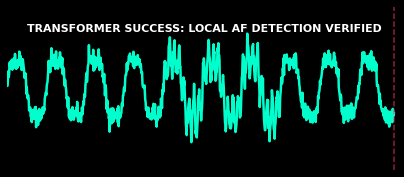

In [3]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

# 1. Set up a dark, high-contrast visual frame suitable for slides
fig, ax = plt.subplots(figsize=(7, 3), facecolor='black')
ax.set_facecolor('black')

# 2. Synthesize a messy, real-world single-lead ECG signal
x = np.linspace(0, 10, 1000)
# Base normal sinus rhythm
y = np.sin(2 * np.pi * 1 * x) + 0.2 * np.sin(2 * np.pi * 3 * x)
# Embed rapid, microscopic irregular waves in the center (Simulating AF)
y[400:700] += 0.5 * np.sin(2 * np.pi * 8 * x[400:700])
# Inject the noisy environment data (PhysioNet real-world challenge style)
np.random.seed(42)
y += np.random.normal(0, 0.15, size=len(x))

# 3. Initialize visual assets (Electric Teal for signal, Hot Pink for scanner)
line, = ax.plot([], [], color='#00FFCC', lw=2.5) 
scan_line = ax.axvline(x=0, color='#FF3366', ls='--', alpha=0.6) 
text_status = ax.text(0.05, 0.85, '', color='white', transform=ax.transAxes, fontsize=11, weight='bold')

ax.set_xlim(0, 10)
ax.set_ylim(-2.5, 2.5)
ax.axis('off')  # Removes distracting graph lines to keep the slide clean

# 4. Define the real-time simulation loop
def init():
    line.set_data([], [])
    scan_line.set_xdata([0])
    text_status.set_text('EDGE SYSTEM: INITIALIZING...')
    return line, scan_line, text_status

def update(frame):
    current_x = x[:frame]
    current_y = y[:frame]
    line.set_data(current_x, current_y)
    
    if frame < len(x):
        scan_line.set_xdata([x[frame]])
    
    # Text changes dynamically mimicking a low-power local Transformer script running
    if frame < 400:
        text_status.set_text('LOCAL INFERENCE STREAMING... [POWER: 2.1W]')
        line.set_color('#00FFCC')
    elif 400 <= frame < 700:
        text_status.set_text('ATTENTION: IRREGULAR R-R INTERVAL DETECTED')
        line.set_color('#FF3366') # Flash the line to pink during the anomaly zone
    else:
        text_status.set_text('TRANSFORMER SUCCESS: LOCAL AF DETECTION VERIFIED')
        line.set_color('#00FFCC')
        
    return line, scan_line, text_status

# 5. Compile and export the final file
ani = animation.FuncAnimation(fig, update, frames=range(0, len(x), 15), init_func=init, blit=True, interval=40)
ani.save('ecg_edge_inference.gif', writer='pillow', fps=25, dpi=120)

print("GIF generated successfully as 'ecg_edge_inference.gif'!")


In [2]:
!powershell.exe -c "get-location" 


Path                                 
----                                 
C:\Project\Research-Project\Notebooks




In [5]:
import matplotlib.pyplot as plt
import matplotlib.animation as animation
import numpy as np

# 1. Set up a dark, high-contrast visual frame suitable for slides
fig, ax = plt.subplots(figsize=(7, 3), facecolor='black')
fig.patch.set_facecolor('black')
ax.set_facecolor('black')

# 2. Synthesize a messy, real-world single-lead ECG signal
x = np.linspace(0, 10, 1000)
# Base normal sinus rhythm
y = np.sin(2 * np.pi * 1 * x) + 0.2 * np.sin(2 * np.pi * 3 * x)
# Embed rapid, microscopic irregular waves in the center (Simulating AF)
y[400:700] += 0.5 * np.sin(2 * np.pi * 8 * x[400:700])
# Inject the noisy environment data (PhysioNet real-world challenge style)
np.random.seed(42)
y += np.random.normal(0, 0.15, size=len(x))

# 3. Initialize visual assets (Electric Teal for signal, Hot Pink for scanner)
line, = ax.plot([], [], color='#00FFCC', lw=2.5) 
scan_line = ax.axvline(x=0, color='#FF3366', ls='--', alpha=0.6) 
text_status = ax.text(0.05, 0.85, '', color='white', transform=ax.transAxes, fontsize=11, weight='bold')

ax.set_xlim(0, 10)
ax.set_ylim(-2.5, 2.5)
ax.axis('off')  # Removes distracting graph lines to keep the slide clean

# 4. Define the real-time simulation loop
def init():
    line.set_data([], [])
    scan_line.set_xdata([])
    text_status.set_text('EDGE SYSTEM: INITIALIZING...')
    return line, scan_line, text_status

def update(frame):
    current_x = x[:frame]
    current_y = y[:frame]
    line.set_data(current_x, current_y)
    
    if frame < len(x):
        scan_line.set_xdata([x[frame]])
    else:
        # Hide the scanning line entirely on the last frame
        scan_line.set_xdata([])
    
    # Text changes dynamically mimicking a low-power local Transformer script running
    if frame < 400:
        text_status.set_text('LOCAL INFERENCE STREAMING... [POWER: 2.1W]')
        line.set_color('#00FFCC')
    elif 400 <= frame < 700:
        text_status.set_text('ATTENTION: IRREGULAR R-R INTERVAL DETECTED')
        line.set_color('#FF3366') # Flash the line to pink during the anomaly zone
    else:
        text_status.set_text('TRANSFORMER SUCCESS: LOCAL AF DETECTION VERIFIED')
        line.set_color('#00FFCC')
        
    return line, scan_line, text_status

# 5. Compile and export the final file
# We add an extra pad to the frames list so it stays frozen on the final "SUCCESS" layout
frames_list = list(range(0, len(x), 15)) + [len(x)] * 20  # Keeps the last frame frozen for 20 frames duration

ani = animation.FuncAnimation(fig, update, frames=frames_list, init_func=init, blit=True, repeat=False)

# CRITICAL FIX: loop=1 tells Pillow to play the GIF exactly once and freeze on the last frame
ani.save('ecg_edge_inference_once.gif', writer='pillow', fps=25, dpi=120, savefig_kwargs={'facecolor':'black'}, loop=1)

print("GIF generated successfully! It will play once and lock onto the final frame.")


TypeError: Animation.save() got an unexpected keyword argument 'loop'

ValueError: shape mismatch: objects cannot be broadcast to a single shape.  Mismatch is between arg 0 with shape (0,) and arg 1 with shape (2,).

<Figure size 504x216 with 1 Axes>